In [ ]:
# %%
import json
import math
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch, Polygon

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 6)

# ---- file paths: update the match_id file names accordingly ----
MATCHES_CSV   = "matches_df.csv"
LINEUPS_CSV   = "lineups_df.csv"
EVENTS_CSV    = "events_by_match/events_3795221.csv"         # change to your chosen match file #3788741 #3795506 #3795221 #3795220
FRAMES360_CSV = "frames_360_by_match/frames_360_3795221.csv"     # same match_id #3788741 #3795506 #3795221 #3795220



# %%
matches = pd.read_csv(MATCHES_CSV)
lineups = pd.read_csv(LINEUPS_CSV)
events  = pd.read_csv(EVENTS_CSV)
frames  = pd.read_csv(FRAMES360_CSV)

print("matches:", matches.shape, "| lineups:", lineups.shape, "| events:", events.shape, "| frames:", frames.shape)
print("\nEvents head columns:", list(events.columns[:20]))
print("Frames head columns:", list(frames.columns))



#initial functions
# %%
def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:
        return json.loads(s)
    except Exception:
        # some CSVs store lists as like "[52.3, 33.2]"
        # or with single quotes — try a fallback
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])
    return None

def draw_pitch(ax=None, linecolor="black", lw=1):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 80)
    ax.set_aspect("equal")
    ax.axis("off")
    # outline & halves
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # boxes
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left box
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right box
    # six-yard
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    # penalty spots & arcs
    ax.plot(12, 40, 'o', color=linecolor, ms=2)
    ax.plot(108, 40, 'o', color=linecolor, ms=2)
    ax.add_patch(Arc((12, 40), 20, 20, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 20, 20, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    # center circle
    ax.add_patch(Arc((60, 40), 20, 20, angle=0, theta1=0, theta2=360, ec=linecolor, lw=lw))
    return ax

def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:    
        return json.loads(s)
    except Exception:
        return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])


#Isolate shots 
# %%
shots = events[events["type"] == "Shot"].copy()
shots["xy"] = shots["location"].apply(try_json).apply(parse_point)
shots["end_xy"] = shots["shot_end_location"].apply(try_json).apply(parse_point) if "shot_end_location" in shots.columns else None

shots["x"] = shots["xy"].apply(lambda p: p[0] if p else np.nan)
shots["y"] = shots["xy"].apply(lambda p: p[1] if p else np.nan)
if "shot_statsbomb_xg" in shots.columns:
    shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
else:
    shots["xg"] = np.nan


#Finding the events we care about 

# Find all shots with xG >= 0.08, all goals, own goals, or fouls that won penalties
shots_high_xg_goal_penalty_wins = pd.concat([
    shots[(shots["xg"] >= 0.08) | (shots['shot_outcome'] == "Goal")],
    events[events['type'] == 'Own Goal Against'],
    events[events.get('foul_won_penalty', False) == True] if 'foul_won_penalty' in events.columns else pd.DataFrame()
], ignore_index=True).sort_values(by=['period', 'timestamp'])

# Get unique possession numbers for these shots, own goals, or penalty-winning fouls
high_xg_possessions = shots_high_xg_goal_penalty_wins["possession"].unique()

# For each possession, retrieve all events in the possession leading up to the shot
possessions_events = {}
for pos_num in high_xg_possessions:
    # All events with this possession number, ordered by event index/id if available
    # (Assumption: "index" or "event_id" or row index gives chronological order, else fallback to DataFrame order)
    possession_events = events[events["possession"] == pos_num]
    # Optional: sort if you have a 'minute', 'second', or 'index' column
    if "index" in possession_events.columns:
        possession_events = possession_events.sort_values("index")
    elif "event_id" in possession_events.columns:
        possession_events = possession_events.sort_values("event_id")
    possessions_events[pos_num] = possession_events


# len(high_xg_possessions)

number_of_interest = 3


matches: (51, 22) | lineups: (2345, 10) | events: (4691, 115) | frames: (53495, 7)

Events head columns: ['fifty_fifty', 'bad_behaviour_card', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'block_save_block', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_other', 'clearance_right_foot', 'counterpress', 'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun']
Frames head columns: ['id', 'match_id', 'visible_area', 'teammate', 'actor', 'keeper', 'location']


/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_31443/358557619.py:1082: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/Users/finneganlaister-smith/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128683 (\N{NO ENTRY SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


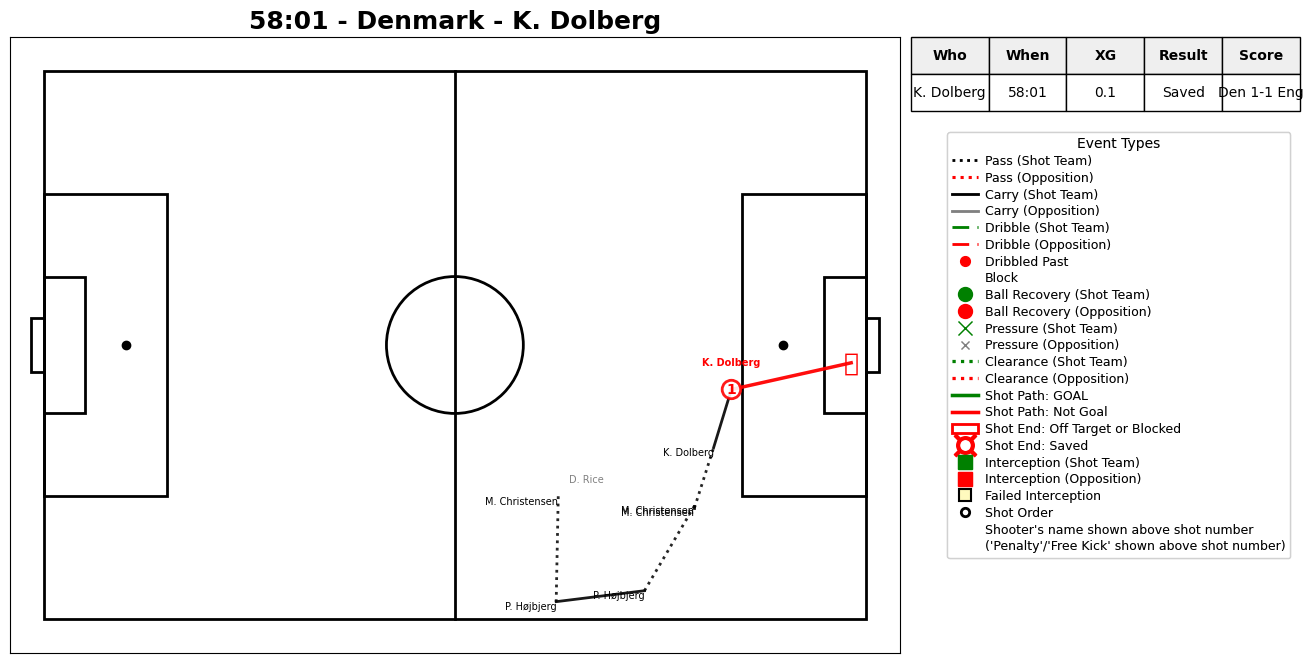

In [10]:
#PLOT CODE FOR SHOT SCENE

# Only look at events for a single possession at a time
single_possession_num = high_xg_possessions[number_of_interest]

df = possessions_events[single_possession_num]

cols_first = [
    "type", "minute", "timestamp", "second", "location", "play_pattern", "player", "position", "shot_statsbomb_xg",
    "possession", "possession_team", "pass_angle", "pass_end_location", "pass_height", "pass_length",
    "pass_recipient", "pass_technique", "team", "period", 
]
cols_first = [c for i, c in enumerate(cols_first) if c not in cols_first[:i]]

def reorder_cols(df, cols_first):
    all_cols = df.columns.tolist()
    first = [c for c in cols_first if c in all_cols]
    rest = [c for c in all_cols if c not in first]
    return df[first + rest]

reordered_df = reorder_cols(df, cols_first)
reordered_df = reordered_df.copy()
reordered_df["source_possession"] = single_possession_num

# Make sure timestamps are sorted.
reordered_df = reordered_df.sort_values("timestamp")

shot_filter = (
    (
        (reordered_df['type'] == 'Shot') & (
            (reordered_df['shot_statsbomb_xg'] >= 0.08) |
            (reordered_df['shot_outcome'] == 'Goal')
        )
    )
    |
    (reordered_df['type'] == 'Own Goal Against')
    |
    (
        (reordered_df['type'] == 'Foul Won') &
        (reordered_df.get('foul_won_penalty', False) == True)
    )
)
shot_row = reordered_df[shot_filter]

if not shot_row.empty and not (shot_row['shot_type'] == 'Penalty').any():
    shot_minute = shot_row.iloc[-1]['minute']
    shot_second = shot_row.iloc[-1]['second']
    shot_abs_time = shot_minute * 60 + shot_second
    reordered_df = reordered_df.copy()
    reordered_df['abs_time'] = reordered_df['minute'] * 60 + reordered_df['second']
    reordered_df_special = reordered_df[
        (reordered_df['abs_time'] >= shot_abs_time - 10) &
        (reordered_df['abs_time'] <= shot_abs_time)
    ]
    reordered_df_special = reordered_df_special.drop(columns=['abs_time'])
else:
    if (shot_row['shot_type'] == 'Penalty').any():
        reordered_df_special = reordered_df#.iloc[0:0]
    else:
        reordered_df_special = reordered_df.iloc[0:0]

# --- Begin new code: time window adjustment (WITH TIMESTAMP CONVERSION) ---
import numpy as np
import ast
import pandas as pd

def convert_timestamp_to_seconds(timestamp_value):
    # Accepts "hh:mm:ss.sss" (like '00:34:37.080') or already numeric types.
    if isinstance(timestamp_value, (float, int, np.floating, np.integer)):
        return float(timestamp_value)
    if isinstance(timestamp_value, pd.Timedelta):
        return timestamp_value.total_seconds()
    if isinstance(timestamp_value, str):
        # Parse format: "hh:mm:ss[.sss]" (e.g., "00:34:37.080")
        try:
            parts = timestamp_value.split(":")
            if len(parts) == 3:
                hours = int(parts[0])
                minutes = int(parts[1])
                seconds = float(parts[2])
                return hours * 3600 + minutes * 60 + seconds
            elif len(parts) == 2:
                # fallback: "mm:ss[.sss]"
                minutes = int(parts[0])
                seconds = float(parts[1])
                return minutes * 60 + seconds
            elif len(parts) == 1:
                # Just seconds
                return float(parts[0])
        except Exception:
            return np.nan
    return np.nan

if not reordered_df_special.empty \
    and 'timestamp' in reordered_df_special.columns \
    and not pd.isnull(reordered_df_special['timestamp'].min()) \
    and not pd.isnull(reordered_df_special['timestamp'].max()):

    # Convert all timestamps in this frame to seconds for comparison
    ts_min_raw = reordered_df_special['timestamp'].min()
    ts_max_raw = reordered_df_special['timestamp'].max()
    ts_min = convert_timestamp_to_seconds(ts_min_raw)
    ts_max = convert_timestamp_to_seconds(ts_max_raw)
    ts_range = ts_max - ts_min

    # If window of timestamps is less than 3 sec:
    if ts_range < 3:
        # We want to include all events back to 5s before the first event in reordered_df_special (by minute/second)
        sec_min = reordered_df_special['second'].min()
        min_min = reordered_df_special.loc[reordered_df_special['second'].idxmin(), 'minute']
        if sec_min >= 5:
            new_minute = min_min
            new_second = sec_min - 5
        else:
            # go to previous minute
            new_minute = min_min - 1
            if sec_min - 5 < 0:
                new_second = 60 + (sec_min - 5)  # example: 4-5 == -1 => 59
            else:
                new_second = sec_min - 5

        # Make sure minute is not negative
        new_minute = max(new_minute, 0)
        # Compose new abs_time threshold
        abs_time_threshold = new_minute * 60 + new_second

        # Find the latest shot (end) again to ensure consistent upper bound
        if not shot_row.empty:
            last_shot_minute = shot_row.iloc[-1]['minute']
            last_shot_second = shot_row.iloc[-1]['second']
            last_shot_abs_time = last_shot_minute * 60 + last_shot_second
        else:
            last_shot_abs_time = None

        reordered_df = reordered_df.copy()
        events['abs_time'] = events['minute'] * 60 + events['second']
        # For the window, use [abs_time_threshold, last_shot_abs_time] if last_shot_abs_time available, else up through max
        if last_shot_abs_time is not None:
            if (shot_row['shot_type'] == 'Penalty').any():
                0==0
            else:
                reordered_df_special = events[
                    (events['abs_time'] >= abs_time_threshold) &
                    (events['abs_time'] <= last_shot_abs_time)
                ]
        else:
            reordered_df_special = events[
                (events['abs_time'] >= abs_time_threshold)
            ]
        if "abs_time" in reordered_df_special.columns:
            reordered_df_special = reordered_df_special.drop(columns=['abs_time'])

        reordered_df_special = reorder_cols(reordered_df_special, cols_first)

# --- End new code ---

shot_team = np.nan
if not reordered_df_special.empty and 'type' in reordered_df_special.columns:
    shot_rows = reordered_df_special[reordered_df_special["type"] == 'Shot']
    own_goal_rows = reordered_df_special[reordered_df_special["type"] == 'Own Goal Against']
    foul_won_rows = None
    if 'foul_won_penalty' in reordered_df_special.columns:
        foul_won_rows = reordered_df_special[
            (reordered_df_special['type'] == 'Foul Won') &
            (reordered_df_special['foul_won_penalty'] == True)
        ]
    else:
        foul_won_rows = reordered_df_special[
            (reordered_df_special['type'] == 'Foul Won')
        ]
    if foul_won_rows is not None and not foul_won_rows.empty:
        shot_team = foul_won_rows['team'].iloc[0]
    elif not shot_rows.empty:
        shot_team = shot_rows['team'].iloc[0]
    elif not own_goal_rows.empty:
        own_goal_team = own_goal_rows['team'].iloc[0]
        teams_in_possession = pd.unique(reordered_df_special['team'].dropna())
        shot_team_candidates = [t for t in teams_in_possession if t != own_goal_team]
        if len(shot_team_candidates) == 1:
            shot_team = shot_team_candidates[0]
        elif len(shot_team_candidates) == 0:
            shot_team = np.nan
        else:
            shot_team = shot_team_candidates[0]
    else:
        shot_team = np.nan
else:
    shot_team = np.nan

# --- LOGIC FOR HIGH TURNOVER, ADJUSTED: excludes Goal Keeper events from interleaving events ---
high_turnover_list = []

if not reordered_df_special.empty:
    reordered_df_special = reordered_df_special.copy()
    events_arr = reordered_df_special.reset_index(drop=False)  # keep original indices for edge cases
    for cur_idx, row in events_arr.iterrows():
        is_high = False
        if row.get('type', None) in ('Ball Recovery', 'Interception'):
            loc = row.get('location', None)
            # Only consider for shot team, and location in advanced half
            is_shot_team_ev = False
            if 'team' in row and row['team'] == shot_team:
                is_shot_team_ev = True
            # Evaluate location
            if isinstance(loc, str):
                try:
                    loc_eval = ast.literal_eval(loc)
                    if isinstance(loc_eval, (list, tuple)):
                        loc = loc_eval
                except Exception:
                    loc = None
            high_x = (isinstance(loc, (list, tuple)) and len(loc) == 2 and float(loc[0]) > 60)

            if is_shot_team_ev and high_x:
                # --- LOGIC FOR HIGH TURNOVER CHECK with Goal Keeper exclusion ---
                # 1. Step backwards to previous event for shot_team (if any)
                start_idx = None
                for prev_idx in range(cur_idx-1, -1, -1):
                    prev_row = events_arr.iloc[prev_idx]
                    if prev_row.get('team', None) == shot_team:
                        start_idx = prev_idx
                        break
                # 2. Look at the slice between previous shot team event (start_idx+1) and this row (cur_idx), inclusive of previous, exclusive of self
                #    If no such slice (start_idx is None), then use up to start (special/corner case: treat as not high turnover)
                # 3. If any row in that range (start_idx+1, ..., cur_idx-1) has team == [not shot team]
                #    but skip any where type == 'Goal Keeper'
                has_other_team_event = False
                if start_idx is not None:
                    opp_team_slice = events_arr.iloc[start_idx+1 : cur_idx]
                    for _, opp_row in opp_team_slice.iterrows():
                        # Exclude Goal Keeper event types from consideration
                        if opp_row.get('type', None) in ('Goal Keeper', 'Pressure', 'Duel', 'Block'):
                            continue
                        opteam = opp_row.get('team', None)
                        if opteam != shot_team and pd.notna(opteam):
                            has_other_team_event = True
                            break
                # If there are no events between (i.e., start_idx == cur_idx-1), then opp_team_slice is empty and has_other_team_event remains False
                # ONLY set is_high if has_other_team_event
                if has_other_team_event:
                    is_high = True
                # otherwise is_high remains False
                # (if there's no previous shot team event, treat it as not high turnover; i.e., those with no prior shot team events, skip yellow)
        high_turnover_list.append(is_high)
    reordered_df_special['High Turnover?'] = high_turnover_list
else:
    reordered_df_special['High Turnover?'] = []

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_pitch(ax=None, color='black', lw=2):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    ax.add_patch(patches.Rectangle((0, 0), 120, 80, fill=False, edgecolor=color, lw=lw))
    ax.plot([60, 60], [0, 80], color=color, lw=lw)
    ax.add_patch(patches.Rectangle((0, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((102, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((0, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((114, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    cc = plt.Circle((60, 40), 10, color=color, fill=False, lw=lw)
    ax.add_patch(cc)
    ax.plot(12, 80-40, marker='o', color=color)
    ax.plot(108, 80-40, marker='o', color=color)
    ax.add_patch(patches.Rectangle((-2, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((120, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.set_xlim(-5, 125)
    ax.set_ylim(-5, 85)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')
    return ax

def get_xy(loc_field):
    import numpy as np
    if isinstance(loc_field, (list, tuple)) and len(loc_field) >= 2:
        return float(loc_field[0]), float(loc_field[1])
    elif isinstance(loc_field, str):
        try:
            arr = eval(loc_field)
            if isinstance(arr, (list, tuple)) and len(arr) >= 2:
                return float(arr[0]), float(arr[1])
        except:
            pass
    return (np.nan, np.nan)

def flip_y(y):
    if y is None:
        return None
    import numpy as np
    if np.isnan(y):
        return y
    return 80 - y

def flip_x(x):
    if x is None:
        return None
    import numpy as np
    if np.isnan(x):
        return x
    return 120 - x

def team_is_shot_team(event_row, shot_team):
    return (event_row.get('team', None) == shot_team)

def plot_squiggly(ax, x1, y1, x2, y2, color='gray', lw=1, zorder=3):
    import numpy as np
    t = np.linspace(0, 1, 100)
    dx = x2 - x1
    dy = y2 - y1
    length = np.sqrt(dx*dx + dy*dy)
    if length < 1e-2:
        return
    ortho_x = -dy / length
    ortho_y = dx / length
    A = min(0.8, 0.06 * length)
    freq = 8
    squiggle = A * np.sin(2 * np.pi * freq * t)
    x = x1 + dx * t + squiggle * ortho_x
    y = y1 + dy * t + squiggle * ortho_y
    ax.plot(x, y, color=color, linewidth=lw, alpha=0.75, zorder=zorder)

def format_player_name(full_name):
    if not isinstance(full_name, str) or len(full_name.strip()) == 0:
        return ""
    parts = full_name.split()
    if len(parts) == 1:
        return parts[0]
    first = parts[0]
    last = parts[-1]
    return f"{first[0]}. {last}"

import numpy as np

ht_x_thresholds = []
if 'High Turnover?' in reordered_df_special.columns:
    for _, row in reordered_df_special.iterrows():
        if row.get("High Turnover?", False):
            x, y = get_xy(row.get("location"))
            if not np.isnan(x):
                ht_x_thresholds.append(x)
ht_x_thresholds = sorted(set(ht_x_thresholds))

shots = reordered_df_special[reordered_df_special['type'] == 'Shot'].sort_values(['minute','second','timestamp'] if 'timestamp' in reordered_df_special.columns else ['minute','second'])
shot_indices = list(shots.index)
shot_numbers = {idx: num+1 for num, idx in enumerate(shot_indices)}
shot_player_names = {idx: shots.loc[idx].get('player', '') for idx in shot_indices}

shot_types_per_shot = {}
if not shots.empty and 'shot_type' in shots.columns:
    for idx, row in shots.iterrows():
        stype = row['shot_type']
        if isinstance(stype, str) and stype.strip() != "":
            if stype.strip().lower() == "penalty":
                shot_types_per_shot[idx] = "Penalty"
            elif stype.strip().lower() == "free kick":
                shot_types_per_shot[idx] = "Free Kick"

def get_passes_deflected_flags(df):
    events = list(df.iterrows())
    pass_deflected = {}
    for idx in range(len(events)):
        ev_idx, ev = events[idx]
        if ev.get("type", None) == "Pass" and team_is_shot_team(ev, shot_team):
            immediate_block = False
            if idx + 1 < len(events):
                next_idx, next_ev = events[idx+1]
                if next_ev.get("type") == "Block" and not team_is_shot_team(next_ev, shot_team):
                    immediate_block = True
            own_deflected = False
            pd_col = ev.get('pass_deflected', None)
            if pd_col is True or (isinstance(pd_col, (np.bool_, bool)) and pd_col):
                own_deflected = True
            pass_deflected[ev_idx] = immediate_block or own_deflected
    return pass_deflected

pass_deflected_flags = get_passes_deflected_flags(reordered_df_special)

def get_shots_deflected_flags(df):
    events = list(df.iterrows())
    shot_deflected = {}
    for idx in range(len(events)):
        ev_idx, ev = events[idx]
        if ev.get("type", None) == "Shot" and team_is_shot_team(ev, shot_team):
            if idx + 1 < len(events):
                next_idx, next_ev = events[idx+1]
                if next_ev.get("type") == "Block" and not team_is_shot_team(next_ev, shot_team):
                    shot_deflected[ev_idx] = True
                else:
                    shot_deflected[ev_idx] = False
            else:
                shot_deflected[ev_idx] = False
    return shot_deflected

shot_deflected_flags = get_shots_deflected_flags(reordered_df_special)

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16,8))
gs = gridspec.GridSpec(1, 2, width_ratios=[7, 2], wspace=0.01)
ax = fig.add_subplot(gs[0])

for xthresh in ht_x_thresholds:
    ax.add_patch(
        patches.Rectangle(
            (xthresh, 0),
            120 - xthresh, 80,
            facecolor='#fdfdbb',
            edgecolor='none',
            zorder=0,
            alpha=0.78 if len(ht_x_thresholds)==1 else 0.55
        )
    )
draw_pitch(ax=ax)

# ---- Inserted code to handle artificial "carry" between Ball Receipt and Pass ----
# We'll precompute the indices and info so we can easily draw them during the plotting loop:
artificial_carry_pairs = []
rows_list = list(reordered_df_special.iterrows())


for n in range(len(rows_list) - 1):
    i1, ev1 = rows_list[n]
    i2, ev2 = rows_list[n + 1]
    # Check: Ball Receipt* followed by Pass, and are on the same team, and both have a location
    if (
        ev1.get("type", None) == "Ball Receipt*"
        and ev2.get("type", None) == "Pass"
        and ev1.get("player", None) == ev2.get("player", None)  # optionally require same player
    ):
        start_x, start_y = get_xy(ev1.get('location'))
        end_x, end_y = get_xy(ev2.get('location'))
        if not (np.isnan(start_x) or np.isnan(end_x)):
            # X location at least 3m apart?
            if abs(end_x - start_x) >= 3.0:
                # Team colorization: match what normal carry would do
                carry_team = ev2.get("team", None)
                artificial_carry_pairs.append( ( (start_x, start_y), (end_x, end_y), carry_team, ev2.get('player', None) ) )
# Now: for quick lookup, build a set of pairs of original row indices for which we're drawing an artificial carry
artificial_carry_indices = set()
for n in range(len(rows_list) - 1):
    i1, ev1 = rows_list[n]
    i2, ev2 = rows_list[n + 1]
    if (
        ev1.get("type", None) == "Ball Receipt*"
        and ev2.get("type", None) == "Pass"
        and ev1.get("player", None) == ev2.get("player", None)
    ):
        start_x, start_y = get_xy(ev1.get('location'))
        end_x, end_y = get_xy(ev2.get('location'))
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if abs(end_x - start_x) >= 3.0:
                artificial_carry_indices.add((i1, i2))

# --- PRECOMPUTE Interception -> shot team Ball Receipt* locations for special plotting
special_intercept_ballreceipt_indices = set()
special_intercept_ballreceipt_locs = []
for n in range(len(rows_list)-1):
    i1, ev1 = rows_list[n]
    i2, ev2 = rows_list[n+1]
    if (
        ev1.get("type", None) == "Interception"
        and not team_is_shot_team(ev1, shot_team)
        and ev2.get("type", None) == "Ball Receipt*"
        and team_is_shot_team(ev2, shot_team)
    ):
        # Both events have a location?
        x, y = get_xy(ev1.get('location'))
        if not (np.isnan(x)):
            special_intercept_ballreceipt_indices.add(i1)
            special_intercept_ballreceipt_locs.append((x, y))
# --


# Plot all event types as before -- but after normal carries, we will plot these "fake" carries.
for i, event in reordered_df_special.iterrows():
    typ = event.get('type', None)
    if pd.isna(typ): continue
    player = event.get('player', None)
    player_short = format_player_name(player)

    # (... plotting code unchanged ...)
    # [everything below here remains unchanged from your original]
     # Own Goal logic remains unchanged
    if typ == "Own Goal Against":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('shot_end_location')) if 'shot_end_location' in event and pd.notna(event['shot_end_location']) else (np.nan, np.nan)
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        start_x_flipped = flip_x(start_x)
        if not np.isnan(start_x) and not np.isnan(end_x):
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='red', linestyle=':', lw=4.0, alpha=0.96, zorder=15)
        if player_short:
            ax.text(start_x_flipped, start_y_flipped, "OG", fontsize=8, color='red', verticalalignment='bottom', horizontalalignment='right', fontweight='bold', zorder=41)
            ax.text(start_x_flipped, start_y_flipped, player_short, fontsize=8, color='red', verticalalignment='top', horizontalalignment='right', fontweight='bold', zorder=41)
        continue

    # ---------- DUEL AND DISPOSSESSED HANDLING (NEW SECTION) ----------
    if typ == "Duel":
        x, y = get_xy(event.get('location'))
        # y_flipped = flip_y(y)
        x_flipped = flip_x(x)
        duel_color = '#ffc0cb'
        duel_fontsize = 7
        if player_short:
            ax.text(x_flipped, y, player_short, fontsize=duel_fontsize, color=duel_color, fontweight='bold', verticalalignment='center', horizontalalignment='center', zorder=55)
        continue

    if typ == "Dispossessed":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        marker_size = 21
        marker_lw = 2.5
        if team_is_shot_team(event, shot_team):
            ax.plot(x, y_flipped, marker='o', markersize=marker_size, markeredgecolor='green', markerfacecolor='none', lw=marker_lw, zorder=30)
        else:
            ax.plot(flip_x(x), y, marker='o', markersize=marker_size, markeredgecolor='red', markerfacecolor='none', lw=marker_lw, zorder=30)
        continue

    # --------------- FOUL WON / FOUL COMMITTED HANDLING (NEW SECTION) -------------------
    if typ == "Foul Won":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        txt = "FOULED"
        if team_is_shot_team(event, shot_team):
            ax.text(x, y_flipped, txt, fontsize=10, color='green', verticalalignment='bottom', horizontalalignment='center', fontweight='bold', zorder=58)
        else:
            ax.text(flip_x(x), y, txt, fontsize=10, color='red', verticalalignment='bottom', horizontalalignment='center', fontweight='bold', zorder=58)
        continue

    if typ == "Foul Committed":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if player_short:
            if team_is_shot_team(event, shot_team):
                ax.text(x, y_flipped, player_short, fontsize=7, color='green', verticalalignment='top', horizontalalignment='center', fontweight='bold', zorder=57)
            else:
                ax.text(flip_x(x), y, player_short, fontsize=7, color='red', verticalalignment='top', horizontalalignment='center', fontweight='bold', zorder=57)
        continue

    if typ == "Pass" and not team_is_shot_team(event, shot_team):
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))
        start_x_flipped = flip_x(start_x)
        end_x_flipped = flip_x(end_x)
        start_y_flipped = flip_y(start_y)
        end_y_flipped = end_y
        pass_type = event.get('pass_type', None)
        if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
            ax.plot([start_x_flipped, end_x_flipped], [start_y_flipped, end_y_flipped],
                    color='red', linestyle=':', lw=2.2, alpha=0.92, zorder=13)
            if player_short:
                ax.text(start_x_flipped, start_y_flipped, player_short, fontsize=7,
                        color='red', verticalalignment='top', horizontalalignment='right', zorder=40)
            if isinstance(pass_type, str) and pass_type.strip().lower() == "corner":
                ax.text(start_x_flipped, start_y_flipped + 2.2, "Corner", fontsize=7, color='#9467bd',
                        ha='center', va='bottom', fontweight='bold', zorder=42)
        continue

    if typ == "Pass" and team_is_shot_team(event, shot_team):
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        is_deflected = pass_deflected_flags.get(i, False)
        pass_type = event.get('pass_type', None)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if is_deflected:
                plot_squiggly(ax, start_x, start_y_flipped, end_x, end_y_flipped, color='black', lw=2, zorder=2)
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle=':', lw=2, alpha=0.45, zorder=2)
            else:
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle=':', lw=2, alpha=0.85, zorder=2)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
            if isinstance(pass_type, str) and pass_type.strip().lower() == "corner":
                ax.text(start_x, start_y_flipped + 2.2, "Corner", fontsize=7, color='#9467bd',
                        ha='center', va='bottom', fontweight='bold', zorder=42)
        continue

    if typ == "Carry":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('carry_end_location'))
        if team_is_shot_team(event, shot_team):
            start_y_flipped = flip_y(start_y)
            end_y_flipped = flip_y(end_y)
            if not (np.isnan(start_x) or np.isnan(end_x)):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
        else:
            start_x_flipped = flip_x(start_x)
            end_x_flipped = flip_x(end_x)
            if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
                ax.plot([start_x_flipped, end_x_flipped], [start_y, end_y], color='gray', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x_flipped, start_y, player_short, fontsize=7, color='gray', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    if typ == "Dribble":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('dribble_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if team_is_shot_team(event, shot_team):
            line_color = 'green'
            label_color = 'green'
        else:
            line_color = 'red'
            label_color = 'red'
        if (not np.isnan(start_x)) and (not np.isnan(end_x)):
            plot_squiggly(ax, start_x, start_y_flipped, end_x, end_y_flipped, color=line_color, lw=2, zorder=4)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color=label_color, verticalalignment='top', horizontalalignment='left', zorder=40)
        continue

    if typ == "Dribbled Past":
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        if not np.isnan(x):
            ax.plot(x_flipped, y, marker='o', color='red', markersize=7, markeredgewidth=1.7, zorder=9)
            if player_short:
                ax.text(x_flipped, y, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='left', zorder=40)
        continue

    if typ == "Block" and not team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        y_flipped = y
        if not np.isnan(x_flipped):
            ax.text(x_flipped, y_flipped, "BLOCK", fontsize=8, ha='center', va='center', color='red', fontweight='bold', zorder=8, rotation=90)
            if player_short:
                x_text = flip_x(x)
                y_text = y
                ax.text(x_text, y_text, player_short, fontsize=7, color='red',
                        verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    if typ == "Block" and team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            ax.text(x, y_flipped, "BLOCK", fontsize=8, ha='center', va='center', color='green', fontweight='bold', zorder=8, rotation=-90)
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color='green', verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    if typ == "Ball Recovery":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            if team_is_shot_team(event, shot_team):
                ax.plot(x, y_flipped, marker='o', color='green', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'green'
            else:
                ax.plot(x, y_flipped, marker='o', color='red', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'red'
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='semibold')
        continue

    if typ == "Pressure":
        x, y = get_xy(event.get('location'))
        if team_is_shot_team(event, shot_team):
            y_flipped = flip_y(y)
            if not np.isnan(x):
                ax.plot(x, y_flipped, marker='x', color='green', markersize=15, markeredgewidth=3, zorder=6)
                txt_color = 'green'
                if player_short:
                    ax.text(x, y_flipped, player_short, fontsize=7, color='green', verticalalignment='top', horizontalalignment='center', zorder=40)
        else:
            x_flipped = flip_x(x)
            y_flipped = y
            if not np.isnan(x_flipped):
                if player_short:
                    ax.text(x_flipped, y_flipped, player_short, fontsize=7, color='gray',
                            verticalalignment='top', horizontalalignment='center', zorder=40)
        continue

    if typ == "Clearance":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('clearance_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if team_is_shot_team(event, shot_team):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='green', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'green'
            else:
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='red', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'red'
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='bottom', horizontalalignment='right', zorder=40)
        continue

    if typ == "Shot":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('shot_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        outcome = event.get('shot_outcome', '').lower() if event.get('shot_outcome') is not None else ""
        if outcome == "goal":
            line_color = "green"
        else:
            line_color = "red"
        is_deflected_shot = shot_deflected_flags.get(i, False)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if is_deflected_shot:
                plot_squiggly(ax, start_x, start_y_flipped, end_x, end_y_flipped, color=line_color, lw=2.5, zorder=10)
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color=line_color, linestyle='-', lw=2.5, alpha=0.45, zorder=10)
            else:
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped],
                        color=line_color, linestyle='-', lw=2.5, alpha=0.95, zorder=10)
            if outcome == 'off target' or outcome == 'blocked':
                circ = plt.Circle((end_x, end_y_flipped), 1.5, fill=False, edgecolor='red', lw=2.5, zorder=15)
                ax.add_patch(circ)
            elif outcome == 'saved':
                ax.text(end_x, end_y_flipped, "🚫", fontsize=18, ha='center', va='center', color='red', zorder=15)
            shot_num = shot_numbers.get(i)
            shot_player = shot_player_names.get(i, player)
            shot_player_short = format_player_name(shot_player)
            shot_type_note = ""
            if i in shot_types_per_shot:
                if shot_types_per_shot[i] == "Penalty":
                    shot_type_note = "Penalty"
                elif shot_types_per_shot[i] == "Free Kick":
                    shot_type_note = "Free Kick"
            if shot_num is not None:
                y_offset_for_number = 0
                y_offset_for_shooter = 3.2
                y_offset_for_shottype = 6.2
                if shot_type_note:
                    ax.text(start_x, start_y_flipped + y_offset_for_shottype, shot_type_note, fontsize=8, color=line_color,
                            fontweight='bold', verticalalignment='bottom', horizontalalignment='center', zorder=52)
                ax.text(start_x, start_y_flipped, f"{shot_num}", fontsize=10, color=line_color, fontweight='bold',
                        verticalalignment='center', horizontalalignment='center', zorder=50, bbox=dict(boxstyle="circle,pad=0.16", fc="white", ec=line_color, lw=2, alpha=0.9))
                if shot_player_short:
                    ax.text(start_x, start_y_flipped + y_offset_for_shooter, shot_player_short, fontsize=7, color=line_color, fontweight='bold',
                            verticalalignment='bottom', horizontalalignment='center', zorder=51)
            elif player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='center', zorder=40, fontweight='bold')
        continue

    if typ == "Interception":
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        y_flipped = flip_y(y)
        is_shot_team = team_is_shot_team(event, shot_team)
        # Check if this interception is followed immediately by shot team Ball Receipt*
        if i in special_intercept_ballreceipt_indices:
            # Draw a black square with faint yellow fill, smaller size
            if not np.isnan(x):
                # Size reduced
                # Use fill color: faint yellow
                ax.scatter(x_flipped, y, marker='s', s=55, facecolor='#fffabe', edgecolor='black', linewidth=1.5, zorder=8)
                if player_short:
                    ax.text(x_flipped, y, player_short, fontsize=7, color='black', verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='normal')
            continue
        # Standard Interception
        if not np.isnan(x):
            color = 'green' if is_shot_team else 'red'
            if is_shot_team:
                ax.plot(x, y_flipped, marker='s', color=color, markersize=16, markeredgecolor='black', markeredgewidth=2, zorder=7)
                if player_short:
                    ax.text(x, y_flipped, player_short, fontsize=7, color=color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='bold')
            else:
                ax.plot(x_flipped, y, marker='s', color=color, markersize=16, markeredgecolor='black', markeredgewidth=2, zorder=7)
                if player_short:
                    ax.text(x_flipped, y, player_short, fontsize=7, color=color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='normal')
        continue

    if typ == "Ball Receipt*":
        # Ball Receipt* -- mainly just for artificial carry logic, no plotting here
        continue

# --- Draw artificial carries after the event loop ---
for n in range(len(rows_list) - 1):
    i1, ev1 = rows_list[n]
    i2, ev2 = rows_list[n + 1]
    if (i1, i2) in artificial_carry_indices:
        start_x, start_y = get_xy(ev1.get('location'))
        end_x, end_y = get_xy(ev2.get('location'))
        player = ev1.get('player', None)
        player_short = format_player_name(player)
        carry_team = ev2.get("team", None)
        # Color: like carry, black for shot team, gray for opposition
        if team_is_shot_team(ev2, shot_team):
            start_y_flipped = flip_y(start_y)
            end_y_flipped = flip_y(end_y)
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle='-', lw=2, alpha=0.6, zorder=3)
            # No text label for "fake" carries, but if you want, you could:
            # if player_short: ax.text(start_x, start_y_flipped, player_short, fontsize=6, ... )
        else:
            start_x_flipped = flip_x(start_x)
            end_x_flipped = flip_x(end_x)
            ax.plot([start_x_flipped, end_x_flipped], [start_y, end_y], color='gray', linestyle='-', lw=2, alpha=0.6, zorder=3)
            # No text label

import matplotlib.lines as mlines
import matplotlib.patches as mpatches

# Add failed interception legend: black square with faint yellow fill, smaller size
failed_interception_legend = mlines.Line2D(
    [], [], marker='s', 
    markersize=9, 
    markerfacecolor='#fffabe', 
    markeredgecolor='black', 
    markeredgewidth=1.5, 
    linestyle='None', 
    lw=0, 
    color='black', 
    label='Failed Interception'
)

legend_elements = [
    mlines.Line2D([], [], color='black', linestyle=':', lw=2, label='Pass (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.2, label='Pass (Opposition)'),
    mlines.Line2D([], [], color='black', linestyle='-', lw=2, label='Carry (Shot Team)'),
    mlines.Line2D([], [], color='gray', linestyle='-', lw=2, label='Carry (Opposition)'),
    mlines.Line2D([], [], color='green', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Shot Team)'),
    mlines.Line2D([], [], color='red', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Opposition)'),
    mlines.Line2D([], [], color='red', marker='o', markersize=7, lw=0, label='Dribbled Past'),
    mlines.Line2D([], [], color='red', marker='', lw=0, label='Block', linestyle='None'),
    mlines.Line2D([], [], color='green', marker='o', markersize=10, lw=0, label='Ball Recovery (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='o', markersize=10, lw=0, label='Ball Recovery (Opposition)'),
    mlines.Line2D([], [], color='green', marker='x', markersize=10, lw=0, label='Pressure (Shot Team)'),
    mlines.Line2D([], [], color='gray', marker='x', markersize=6, lw=0, label='Pressure (Opposition)'),
    mlines.Line2D([], [], color='green', linestyle=':', lw=2.3, label='Clearance (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.3, label='Clearance (Opposition)'),
    mlines.Line2D([], [], color='green', linestyle='-', lw=2.5, label='Shot Path: GOAL'),
    mlines.Line2D([], [], color='red', linestyle='-', lw=2.5, label='Shot Path: Not Goal'),
    mpatches.Patch(facecolor='none', edgecolor='red', linewidth=2, label='Shot End: Off Target or Blocked', alpha=1),
    mlines.Line2D([], [], color='red', marker='$🚫$', markersize=16, lw=0, label='Shot End: Saved'),
    mlines.Line2D([], [], color='green', marker='s', markersize=10, lw=0, label='Interception (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='s', markersize=10, lw=0, label='Interception (Opposition)'),
    failed_interception_legend,
    mlines.Line2D([], [], marker='o', color='w', markerfacecolor='w', markeredgecolor='black', markeredgewidth=2, lw=0, label='Shot Order'),
    mlines.Line2D([], [], marker=None, color='w', lw=0, label="Shooter's name shown above shot number"),
    mlines.Line2D([], [], marker=None, color='w', lw=0, label="('Penalty'/'Free Kick' shown above shot number)")
]

ax_legend = fig.add_subplot(gs[1])
ax_legend.axis('off')
legend = ax_legend.legend(
    handles=legend_elements,
    loc='center left',
    fontsize=9,
    frameon=True,
    ncol=1,
    title='Event Types',
    borderaxespad=0.5,
    columnspacing=0.6,
    handletextpad=0.5,
    labelspacing=0.3,
    borderpad=0.4,
    handlelength=2.1
)



# --- INFO CARD TABLE FOR SHOT SCENE (RIGHT SUBPLOT, ABOVE LEGEND) ---
import numpy as np
import pandas as pd

# Gather key shot (or penalty/foul-won) info
shot_info = None
info_note = None
who = 'N/A'
when = 'N/A'
xg = 'N/A'
outcome = 'N/A'
score_string = 'N/A'

def to_f_last(name):
    if not isinstance(name, str) or name.strip() == '' or name == 'N/A':
        return 'N/A'
    parts = name.strip().split()
    if len(parts) >= 2:
        return f"{parts[0][0]}. {parts[-1]}"
    else:
        return name

# Get the shot row if available, or penalty/foul-won
if not shot_row.empty:
    sr = shot_row.iloc[-1]
    who = to_f_last(sr.get('player', 'N/A'))
    xg_val = sr.get('shot_statsbomb_xg', 'N/A')
    if isinstance(xg_val, (int, float)):
        xg = round(xg_val, 2)
    else:
        xg = xg_val
    shot_type = sr.get('shot_type', '')
    if isinstance(shot_type, str) and shot_type.strip().lower() == 'penalty':
        info_note = '(Penalty)'
    elif isinstance(shot_type, str) and shot_type.strip().lower() == 'free kick':
        info_note = '(Free Kick)'
    shot_minute = sr.get('minute', None)
    shot_second = sr.get('second', None)
    if shot_minute is not None and shot_second is not None:
        when = f"{int(shot_minute)}:{int(shot_second):02d}"
    outcome = sr.get('shot_outcome', 'N/A')
elif not reordered_df_special.empty and 'Foul Won' in reordered_df_special['type'].values:
    # Foul won penalty logic
    foul_row = reordered_df_special[(reordered_df_special['type']=='Foul Won') & (reordered_df_special.get('foul_won_penalty', False)==True)]
    if not foul_row.empty:
        fr = foul_row.iloc[-1]
        who = to_f_last(fr.get('player', 'N/A'))
        info_note = '(Penalty Won)'
        shot_minute = fr.get('minute', None)
        shot_second = fr.get('second', None)
        if shot_minute is not None and shot_second is not None:
            when = f"{int(shot_minute)}:{int(shot_second):02d}"
        outcome = 'N/A'

if info_note is not None and who != 'N/A':
    who = f"{who} {info_note}"

# Get score at time of shot using full match events DataFrame
if 'events' in globals() and (not shot_row.empty or (not reordered_df_special.empty and 'Foul Won' in reordered_df_special['type'].values)):
    if not shot_row.empty:
        # Use minute and second ONLY, not timestamp
        min_sec = sr['minute'] * 60 + sr['second'] if 'minute' in sr and 'second' in sr else None
    else:
        fr = foul_row.iloc[-1]
        min_sec = fr['minute'] * 60 + fr['second'] if 'minute' in fr and 'second' in fr else None

    # This row_time function ONLY uses minute and second (ignores timestamp)
    def row_time(row):
        if 'minute' in row and 'second' in row:
            return row['minute']*60 + row['second']
        else:
            return None

    target_time = min_sec
    e = events.copy()
    e['event_time'] = e.apply(row_time, axis=1)
    e = e[~pd.isnull(e['event_time'])]
    e = e[e['event_time'] <= target_time]
    teams = pd.unique(e['team'].dropna())
    team_names = list(teams)
    if shot_team in teams:
        st = shot_team
        other_teams = [t for t in teams if t != shot_team]
        ot = other_teams[0] if other_teams else 'Other'
    else:
        st = team_names[0] if team_names else 'Team1'
        ot = team_names[1] if len(team_names) > 1 else 'Team2'
    def score_for(team):
        goals = e[(e.get('shot_outcome', '')=='Goal') & (e.get('team', None)==team)].shape[0]
        own_goals = e[(e['type']=='Own Goal For') & (e.get('team', None)==team)].shape[0]
        return goals + own_goals
    st_score = score_for(st)
    ot_score = score_for(ot)
    score_string = f"{st[:3]} {st_score}-{ot_score} {ot[:3]}"

info_cols = ["Who", "When", 'XG', "Result", "Score"]
info_data = [[who, when, xg, outcome, score_string]]

# Make each of the boxes WIDER:
# Option 1: Set bbox wider than 1 (overflow--will clip), or less tall, or recenter table.
# Option 2: Change the font size smaller, but you asked for wider boxes.
# Option 3: Set width ratios for each column to make columns more proportionate for overflowing text.

# The best way: use bbox to set table itself wider, or tweak subplot size/aspect so the table has more space.
# matplotlib.table does not expose per-column width, but we can manually adjust cell widths after creation.
# Let's extend bbox's width: [0, bottom, width, height], width > 1 will stretch the table horizontally.
# E.g. width=1.42 (or whatever is needed to fit). Might need to tweak further for your plotting layout.

widen_factor = 1.42   # Try 1.3-1.5 depending on your ax_legend width
# To move further right, INCREASE bbox[0] (the "left" parameter)
right_shift = 0.10  # Increase this to shift farther right; try 0.10, 0.20, etc.
info_table = ax_legend.table(
    cellText=info_data,
    colLabels=info_cols,
    loc='upper center',
    cellLoc='center',
    colLoc='center',
    bbox=[-0.21 + right_shift, 0.88, widen_factor, 0.12],  # move table to the right by increasing "left"
)

info_table.auto_set_font_size(False)
info_table.set_fontsize(10)
# Optionally, manually set cell width for each column (equal width only)
cell_dict = info_table.get_celld()
ncols = len(info_cols)
for (row, col), cell in cell_dict.items():
    # Manually set all cell widths to be larger (divide bbox width equally)
    cell.set_width(widen_factor / ncols)
    if row == 0:
        cell.set_text_props(weight='bold', color='black')
        cell.set_facecolor('#efefef')
    cell.set_edgecolor('black')
#end of info card table legend section#


# plt.tight_layout()
ax.set_title(f"Events in Possession {single_possession_num}", fontsize=18, fontweight='bold')
# plt.show()

# --- Draw artificial carries after the event loop ---
for n in range(len(rows_list) - 1):
    i1, ev1 = rows_list[n]
    i2, ev2 = rows_list[n + 1]
    if (i1, i2) in artificial_carry_indices:
        start_x, start_y = get_xy(ev1.get('location'))
        end_x, end_y = get_xy(ev2.get('location'))
        player = ev1.get('player', None)
        player_short = format_player_name(player)
        carry_team = ev2.get("team", None)
        # Color: like carry, black for shot team, gray for opposition
        if team_is_shot_team(ev2, shot_team):
            start_y_flipped = flip_y(start_y)
            end_y_flipped = flip_y(end_y)
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle='-', lw=2, alpha=0.6, zorder=3)
            # No text label for "fake" carries, but if you want, you could:
            # if player_short: ax.text(start_x, start_y_flipped, player_short, fontsize=6, ... )
        else:
            start_x_flipped = flip_x(start_x)
            end_x_flipped = flip_x(end_x)
            ax.plot([start_x_flipped, end_x_flipped], [start_y, end_y], color='gray', linestyle='-', lw=2, alpha=0.6, zorder=3)
            # No text label

import matplotlib.lines as mlines
import matplotlib.patches as mpatches

# Add failed interception legend: black square with faint yellow fill, smaller size
failed_interception_legend = mlines.Line2D(
    [], [], marker='s', 
    markersize=9, 
    markerfacecolor='#fffabe', 
    markeredgecolor='black', 
    markeredgewidth=1.5, 
    linestyle='None', 
    lw=0, 
    color='black', 
    label='Failed Interception'
)

legend_elements = [
    mlines.Line2D([], [], color='black', linestyle=':', lw=2, label='Pass (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.2, label='Pass (Opposition)'),
    mlines.Line2D([], [], color='black', linestyle='-', lw=2, label='Carry (Shot Team)'),
    mlines.Line2D([], [], color='gray', linestyle='-', lw=2, label='Carry (Opposition)'),
    mlines.Line2D([], [], color='green', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Shot Team)'),
    mlines.Line2D([], [], color='red', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Opposition)'),
    mlines.Line2D([], [], color='red', marker='o', markersize=7, lw=0, label='Dribbled Past'),
    mlines.Line2D([], [], color='red', marker='', lw=0, label='Block', linestyle='None'),
    mlines.Line2D([], [], color='green', marker='o', markersize=10, lw=0, label='Ball Recovery (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='o', markersize=10, lw=0, label='Ball Recovery (Opposition)'),
    mlines.Line2D([], [], color='green', marker='x', markersize=10, lw=0, label='Pressure (Shot Team)'),
    mlines.Line2D([], [], color='gray', marker='x', markersize=6, lw=0, label='Pressure (Opposition)'),
    mlines.Line2D([], [], color='green', linestyle=':', lw=2.3, label='Clearance (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.3, label='Clearance (Opposition)'),
    mlines.Line2D([], [], color='green', linestyle='-', lw=2.5, label='Shot Path: GOAL'),
    mlines.Line2D([], [], color='red', linestyle='-', lw=2.5, label='Shot Path: Not Goal'),
    mpatches.Patch(facecolor='none', edgecolor='red', linewidth=2, label='Shot End: Off Target or Blocked', alpha=1),
    mlines.Line2D([], [], color='red', marker='$🚫$', markersize=16, lw=0, label='Shot End: Saved'),
    mlines.Line2D([], [], color='green', marker='s', markersize=10, lw=0, label='Interception (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='s', markersize=10, lw=0, label='Interception (Opposition)'),
    failed_interception_legend,
    mlines.Line2D([], [], marker='o', color='w', markerfacecolor='w', markeredgecolor='black', markeredgewidth=2, lw=0, label='Shot Order'),
    mlines.Line2D([], [], marker=None, color='w', lw=0, label="Shooter's name shown above shot number"),
    mlines.Line2D([], [], marker=None, color='w', lw=0, label="('Penalty'/'Free Kick' shown above shot number)")
]

ax_legend = fig.add_subplot(gs[1])
ax_legend.axis('off')
legend = ax_legend.legend(
    handles=legend_elements,
    loc='center left',
    fontsize=9,
    frameon=True,
    ncol=1,
    title='Event Types',
    borderaxespad=0.5,
    columnspacing=0.6,
    handletextpad=0.5,
    labelspacing=0.3,
    borderpad=0.4,
    handlelength=2.1
)

plt.tight_layout()
ax.set_title(f"{when} - {shot_team} - {who}", fontsize=18, fontweight='bold') #single_possession_num
plt.show()

In [ ]:
#stuff to think about 

    #how would you add a situation where the cross gets played in and nobody heads it? can you? 